# Relationality, single units only → `figure_relationality_good.pdf`

[`../figure_4/figure_relationality.ipynb`](../figure_4/figure_relationality.ipynb),
over **well-isolated single units only** instead of the whole population: the distribution of the
relational-bias model's fitted $\rho$ across neurons, one panel per monkey.

Nothing is refit. This reads the same cache the pooled figure reads and applies the same
selection, with the single-unit cut after it. Which neurons are eligible is the shared,
model-agnostic 2-object modulation criterion, so it is the same population the model comparison
beside it is drawn over.

$\rho = 0$ means the neuron measures object direction from **fixation**, $\rho = 1$ from the
**midpoint of the pair**. Both ends carry an **atom**: $\rho$ is
bounded to $[0, 1]$ because outside it the model is not identifiable, so a neuron whose
optimum sits on a bound lands exactly on it. Read the bars against 0 and 1 as counts of
neurons on a bound, not as a bin's worth of spread.


In [1]:
import matplotlib.pyplot as plt

import common
import relationality_lib as rl
import plot_lib

common.set_style()

# Only the metric's own model is drawn, but the set decides which neurons enter — it must
# contain `relational_bias`, or its fitted parameter is not in `summary`.
MODELS = ('future_field', 'relational_bias')
FIGSIZE = (5.2, 2.9)
N_BINS = 15
XLABEL = 'Relationality (r)'

2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 1339 -> 1339 neurons
single units: 672 of 1339 neurons kept (50%)
  Elgar: 116
  Perle: 556
  Perle: 556 neurons with a fitted bias, median 0.72, 70 at 0, 1 at 1
  Elgar: 116 neurons with a fitted bias, median 0.55, 18 at 0, 0 at 1
saved figure_relationality_good.pdf


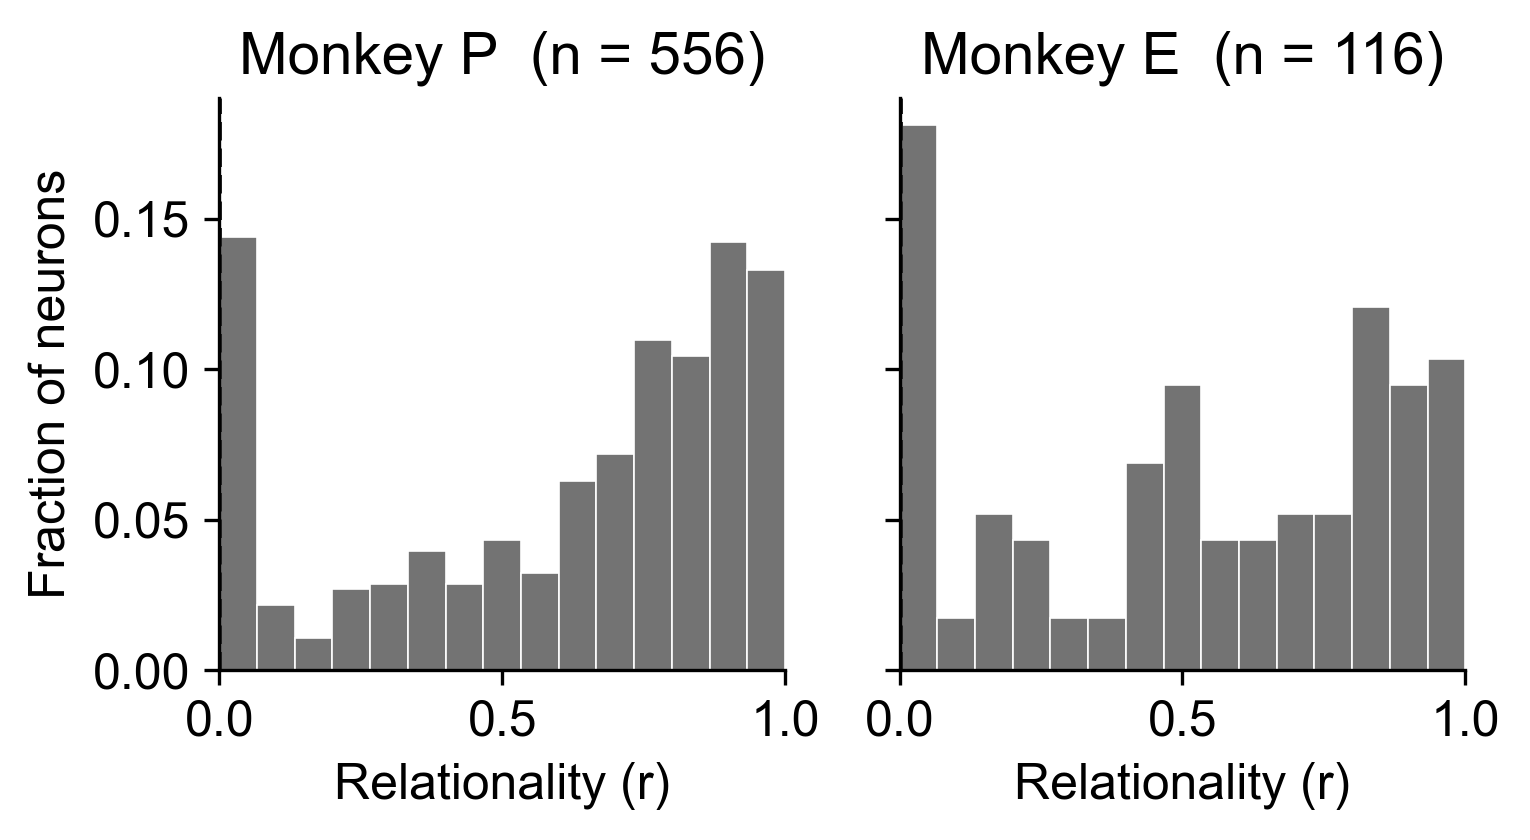

In [2]:
for group, summary in common.selected_fits_good(MODELS):
    biases = rl.biases(summary, verbose=False)
    for subject in plot_lib.levels(biases, 'subject'):
        v = biases[biases['subject'] == subject]['bias']
        print(f'  {subject}: {len(v)} neurons with a fitted bias, median {v.median():.2f}, '
              f'{int((v <= 1e-9).sum())} at 0, {int((v >= 1 - 1e-9).sum())} at 1')

    fig, _ = plot_lib.plot_relationality_distribution(
        biases, figsize=FIGSIZE, bins=N_BINS, xlabel=XLABEL)
    common.save(fig, f'figure_relationality_{group}.pdf')
    plt.show()